# HPD 3 — Workflows y agentes con LangGraph

<figure>
<a
href="https://colab.research.google.com/github/Adamychen/m10_quarto/blob/main/notebooks/bloque2/hpd3-workflows-langgraph.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

> **Competencias:** [CE-2](../index.qmd#sec-competencias-especificas)

> **Objetivos**
>
> - Traducir los patrones de la taxonomía de [02f — Patrones de Diseño
>   de Agentes](02f-patrones-agentes.qmd) a grafos de ejecución con
>   LangGraph
> - Implementar routing, evaluator-optimizer y parallelization con
>   `StateGraph`
> - Añadir human-in-the-loop con `interrupt()` y checkpointing
> - Construir un supervisor multi-agente con `create_agent`
> - Resolver un problema de análisis financiero con el patrón adecuado
>
> ## Materiales
>
> - Librerías: `langgraph`, `langgraph-prebuilt`,
>   `langgraph-checkpoint`, `langchain-openai`, `python-dotenv`
> - LLM: API Llamus US (`https://llamus.cs.us.es/api/v1`, modelo
>   `gemma4:26b`) o local (Ollama con `qwen3:8b`)
> - Prerrequisito: [02e — Agentes Inteligentes](02e-agentes.qmd) y [02f
>   — Patrones de Diseño de Agentes](02f-patrones-agentes.qmd)
>
> ## Pipeline
>
> 1.  **Parte 1 — Patrones de 02f como grafos:** routing,
>     evaluator-optimizer y parallelization con `StateGraph`
> 2.  **Parte 2 — Human-in-the-loop:** interrupt + checkpointing + gate
>     de aprobación
> 3.  **Parte 3 — Multi-agente supervisor:** supervisor con agentes
>     especializados
> 4.  **Parte 4 — Problema aplicado (finanzas):** diseña e implementa el
>     grafo del resumen trimestral
> 5.  **Ejercicios:** extiende los grafos con nuevos nodos y patrones

> **¿Por qué necesitas esto?**
>
> En el HPD 2 construiste un agente ReAct con `create_agent` de
> LangChain: el LLM decidía qué herramienta usar en cada paso, pero el
> flujo era una caja negra. En 02f viste la taxonomía de patrones
> (routing, evaluator-optimizer, parallelization, orchestrator-workers…)
> sobre diagramas. En este taller abres la caja negra: implementas esos
> patrones como grafos donde cada nodo es un paso, cada arista es una
> transición y tú controlas el flujo.
>
> ¿Por qué importa? Porque en producción necesitas flujos
> inspeccionables: saber en qué paso falló, pausar una ejecución para
> pedir aprobación humana o coordinar varios agentes especializados.
> LangGraph es el estándar *de facto* para esto en el ecosistema
> LangChain, y el proyecto integrador final te pide aplicar un patrón de
> la taxonomía de 02f — este taller te da el repertorio en código.

> **Antes de empezar**
>
> Ejecuta **ya** la celda de instalación de más abajo y sigue leyendo
> mientras termina: tarda unos 2 minutos. Si al acabar aparece un aviso
> en rojo sobre *dependency conflicts* (`google-colab`, `requests`,
> `opentelemetry`), ignóralo: son paquetes que trae Colab y no afectan a
> este taller.

In [1]:
!pip install -q langgraph==1.2.2 langgraph-prebuilt==1.1.0 langgraph-checkpoint==4.1.1 langchain-openai==1.2.2 python-dotenv==1.2.2 langchain-core==1.4.0 openai==2.38.0

In [2]:
import os
"""
Setup compartido para la API key de Llamus en todos los notebooks.
Inyectado en cada .qmd/.ipynb vía scripts/sync_setup_keys.py (pre-render).

Orden de resolución:
  1. .env local (python-dotenv)
  2. os.environ ya configurado externamente
  3. Google Colab userdata: secret "LLAMUS_API_KEY" (preferente) o "LLM_API_KEY"

Las celdas posteriores pueden leer la clave con os.environ.get("LLM_API_KEY").
"""

import os


def _load_llm_api_key():
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass

    if not os.getenv("LLM_API_KEY"):
        try:
            from google.colab import userdata
            for name in ("LLAMUS_API_KEY", "LLM_API_KEY"):
                try:
                    value = userdata.get(name)
                    if value:
                        os.environ["LLM_API_KEY"] = value
                        break
                except Exception:
                    continue
        except ImportError:
            pass


_load_llm_api_key()

if os.getenv("LLM_API_KEY"):
    print("✓ LLM_API_KEY cargada.")
else:
    print("⚠️  LLM_API_KEY no encontrada.")
    print("    • Local: crea un archivo .env con LLM_API_KEY=tu_clave")
    print("    • Colab: añade un Secret 🔑 con nombre 'LLAMUS_API_KEY'")

os.environ["TOKENIZERS_PARALLELISM"] = "false"
import warnings
warnings.filterwarnings("ignore")
print("Librerías cargadas correctamente.")

✓ LLM_API_KEY cargada.
Librerías cargadas correctamente.

In [3]:
from langchain_openai import ChatOpenAI

LLM_KEY = os.getenv("LLM_API_KEY")
LLM_URL = os.getenv("LLM_URL", "https://llamus.cs.us.es/api/v1")

if not LLM_KEY:
    print("⚠️  Crea un archivo .env en la raíz con:\n    LLM_API_KEY=tu_api_key\n    Las celdas con LLM mostrarán este aviso.")
else:
    llm = ChatOpenAI(model=os.getenv("LLM_MODEL", "gemma4:26b"), base_url=LLM_URL, api_key=LLM_KEY, temperature=0, max_tokens=2048)
    print("✅ LLM configurado.")

✅ LLM configurado.

------------------------------------------------------------------------

# Parte 1 — Patrones de 02f como grafos

Un grafo de LangGraph tiene tres ingredientes: un estado (un `TypedDict`
que viaja por los nodos), unos nodos (funciones que reciben y devuelven
el estado) y unas aristas (transiciones entre nodos, con
`add_conditional_edges` para ramas). Empezamos traduciendo los tres
patrones de workflow de 02f.

## 1.1 Routing: un clasificador despacha a manejadores especializados

El patrón de routing de 02f tiene el clasificador y los manejadores como
nodos separados. La arista condicional decide el destino:

<figure id="fig-hpd3-routing">
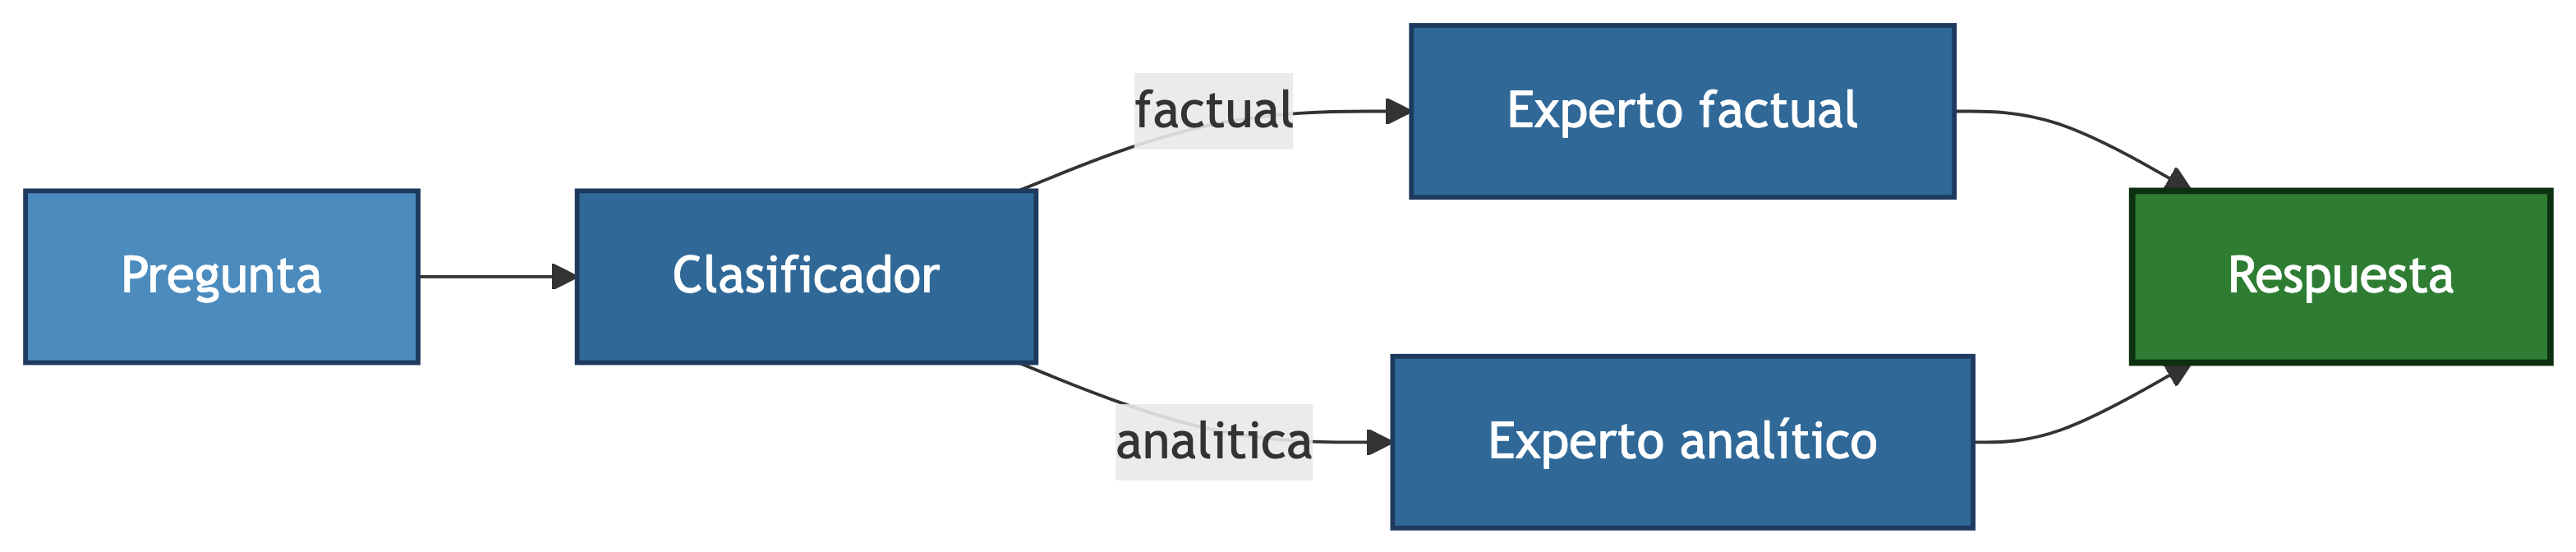
<figcaption>Figure 1</figcaption>
</figure>

In [4]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, END
from langchain_core.messages import HumanMessage

class EstadoRouting(TypedDict):
    pregunta: str
    ruta: str
    respuesta: str

def clasificador(state: EstadoRouting) -> EstadoRouting:
    """El LLM decide la ruta: 'factual' (datos concretos) o 'analitica' (interpretación)."""
    resp = llm.invoke(
        f"Clasifica la pregunta como 'factual' (pide datos concretos) o 'analitica' "
        f"(pide interpretación o análisis). Pregunta: {state['pregunta']}\n"
        "Responde solo con una palabra: factual o analitica"
    )
    ruta = resp.content.strip().lower()
    state["ruta"] = "factual" if ruta.startswith("fact") else "analitica"
    return state

# ─── COMPLETAR: los dos manejadores especializados ───
# TODO: crear experto_factual(state) → llm.invoke con un system prompt
#   de datos concretos y precisos ("si no sabes el dato, dilo")
# TODO: crear experto_analitico(state) → llm.invoke con un system prompt
#   analítico ("causas, tendencias, recomendaciones")
# Ambos guardan el resultado en state["respuesta"]

def experto_factual(state: EstadoRouting) -> EstadoRouting:
    # TODO: resp = llm.invoke([...])
    # TODO: state["respuesta"] = resp.content
    return state  # ← completar

def experto_analitico(state: EstadoRouting) -> EstadoRouting:
    # TODO: resp = llm.invoke([...])
    # TODO: state["respuesta"] = resp.content
    return state  # ← completar

def decidir_ruta(state: EstadoRouting) -> Literal["experto_factual", "experto_analitico"]:
    return "experto_factual" if state["ruta"] == "factual" else "experto_analitico"

grafo_routing = StateGraph(EstadoRouting)
grafo_routing.add_node("clasificador", clasificador)
grafo_routing.add_node("experto_factual", experto_factual)
grafo_routing.add_node("experto_analitico", experto_analitico)

grafo_routing.set_entry_point("clasificador")
grafo_routing.add_conditional_edges("clasificador", decidir_ruta, {
    "experto_factual": "experto_factual",
    "experto_analitico": "experto_analitico",
})
grafo_routing.add_edge("experto_factual", END)
grafo_routing.add_edge("experto_analitico", END)

app_routing = grafo_routing.compile()
print("✅ Grafo de routing compilado")

✅ Grafo de routing compilado

In [5]:
preguntas_routing = [
    "¿Cuál es la población de Sevilla?",
    "¿Por qué crees que bajaron las ventas este trimestre?",
]

if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env")
else:
    for pregunta in preguntas_routing:
        result = app_routing.invoke({"pregunta": pregunta, "ruta": "", "respuesta": ""})
        print(f"\nPREGUNTA: {pregunta}")
        print(f"  Ruta: {result['ruta']}")
        print(f"  Respuesta: {result['respuesta'][:200]}...")

> **¿Qué has construido?**
>
> El clasificador es un nodo más del grafo. `add_conditional_edges`
> recibe una función que devuelve el nombre del nodo destino y un
> diccionario que mapea esos nombres a nodos reales. El estado fluye
> entero: lo que el clasificador escribe en `state["ruta"]` lo leen los
> manejadores. Fíjate en que el coste extra del patrón es solo 1 llamada
> al LLM (la clasificación), igual que en el ejemplo con LangChain de
> 02f.

## 1.2 Evaluator-Optimizer: un generador y un evaluador en bucle

El patrón de 02f tiene un ciclo: el evaluador puntúa la salida del
generador y, si no alcanza el umbral, devuelve la crítica al generador.
En LangGraph los ciclos son aristas condicionales que vuelven a un nodo
anterior:

<figure id="fig-hpd3-evaluator">
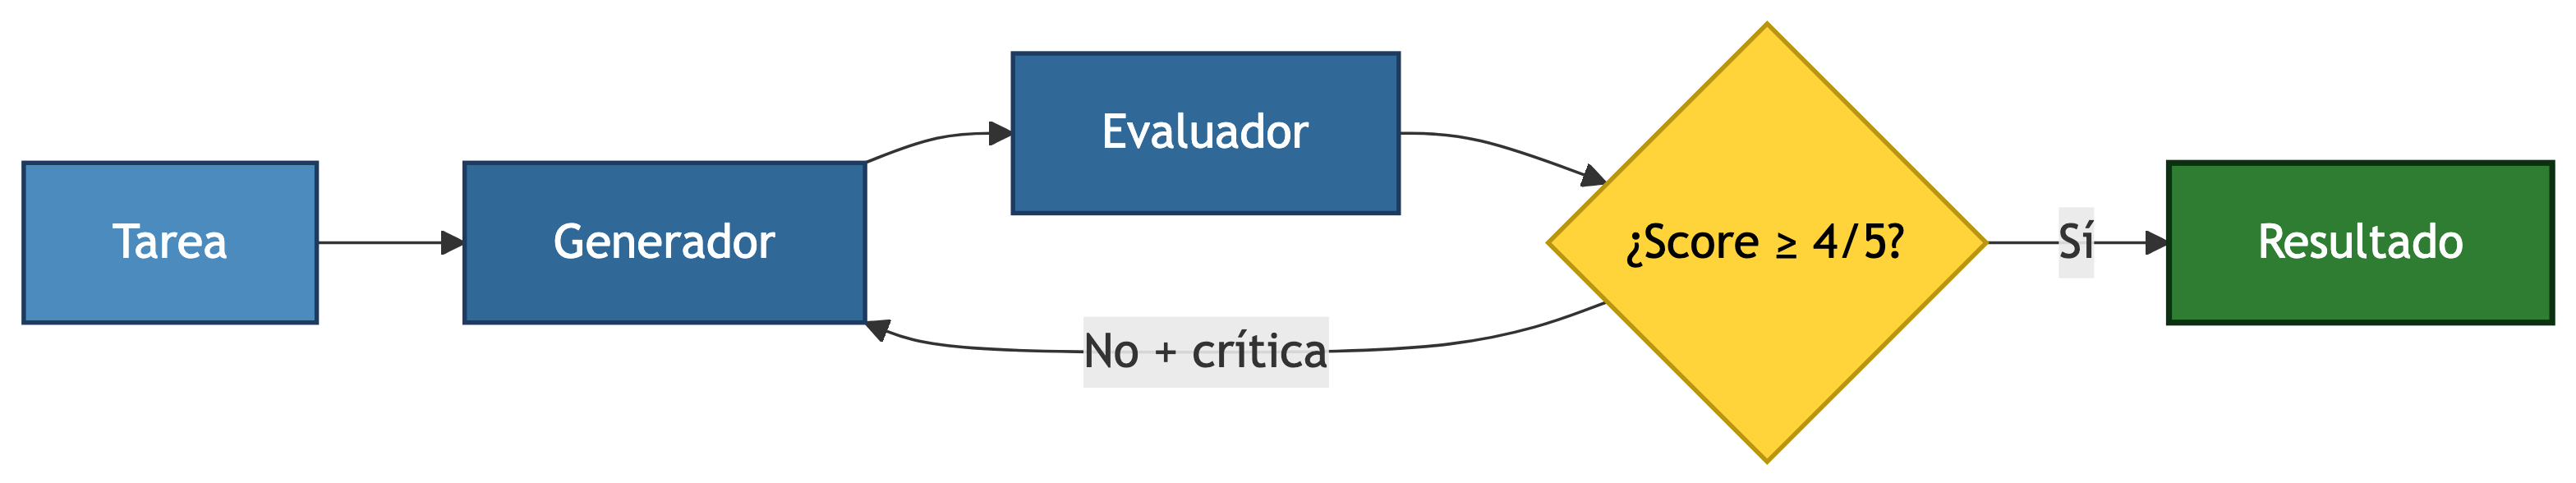
<figcaption>Figure 2</figcaption>
</figure>

In [6]:
class EstadoEvalOpt(TypedDict):
    tarea: str
    borrador: str
    criticas: list
    score: int
    intentos: int

MAX_INTENTOS = 3

def generador(state: EstadoEvalOpt) -> EstadoEvalOpt:
    """Genera o mejora un borrador incorporando las críticas acumuladas."""
    criticas_texto = "\n".join(f"- {c}" for c in state["criticas"]) or "Ninguna (primer intento)."
    prompt = (
        f"Tarea: {state['tarea']}\n\n"
        f"Críticas del evaluador del intento anterior:\n{criticas_texto}\n\n"
        "Escribe la versión del texto incorporando esas críticas. Responde en español, conciso (máx 5 frases)."
    )
    resp = llm.invoke([HumanMessage(content=prompt)])
    state["borrador"] = resp.content
    state["intentos"] += 1
    return state

def evaluador(state: EstadoEvalOpt) -> EstadoEvalOpt:
    """Puntúa el borrador del 1 al 5 y escribe una crítica si no aprueba."""
    resp = llm.invoke(
        f"Evalúa este texto del 1 al 5 (5 = perfecto):\n---\n{state['borrador']}\n---\n"
        "Formato de respuesta: primera línea solo el número, segunda línea la crítica concreta "
        "si el score es < 4, o 'OK' si es >= 4."
    )
    lineas = resp.content.strip().split("\n")
    try:
        state["score"] = int(lineas[0].strip())
    except ValueError:
        state["score"] = 1
    state["criticas"].append(lineas[1].strip() if len(lineas) > 1 else "Mejora la claridad.")
    return state

def comprobar_calidad(state: EstadoEvalOpt) -> str:
    """Arista condicional: aprueba si score >= 4 o se agotaron los intentos."""
    if state["score"] >= 4 or state["intentos"] >= MAX_INTENTOS:
        return "fin"
    return "generador"

grafo_evalopt = StateGraph(EstadoEvalOpt)
grafo_evalopt.add_node("generador", generador)
grafo_evalopt.add_node("evaluador", evaluador)
grafo_evalopt.set_entry_point("generador")
grafo_evalopt.add_edge("generador", "evaluador")
grafo_evalopt.add_conditional_edges("evaluador", comprobar_calidad, {
    "generador": "generador",
    "fin": END,
})
app_evalopt = grafo_evalopt.compile()
print("✅ Grafo evaluator-optimizer compilado")

✅ Grafo evaluator-optimizer compilado

In [7]:
if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env")
else:
    result = app_evalopt.invoke({
        "tarea": "Resume en 5 frases el mecanismo de atención multi-cabeza del Transformer.",
        "borrador": "", "criticas": [], "score": 0, "intentos": 0,
    })
    print(f"\nTarea: {result['tarea']}")
    print(f"Intentos: {result['intentos']} | Score final: {result['score']}/5")
    print(f"\nTexto final:\n{result['borrador']}")

> **¿Cuándo conviene un bucle así?**
>
> El evaluator-optimizer brilla en tareas con criterios de calidad
> claros: informes, traducciones, código que debe pasar tests. El
> presupuesto de reintentos (`MAX_INTENTOS`) evita bucles infinitos y
> controla el coste — mismo principio que la tabla de estrategias de
> replanning de 02f, pero aplicado a calidad.

## 1.3 Parallelization: fan-out con `Send`

El patrón de parallelization de 02f lanza varias llamadas en paralelo y
combina sus salidas. En LangGraph se usa `Send` desde una arista
condicional que genera varias ejecuciones del nodo worker, una por
subtarea. La estructura canónica tiene tres piezas: un nodo despachador
(no-op cuya arista condicional emite los `Send`), el worker que se
ejecuta en paralelo (cada rama recibe un subestado con sus propios
campos) y un nodo join que reúne las ramas:

In [8]:
from typing import Annotated
import operator
from langgraph.types import Send

class EstadoAuditoria(TypedDict):
    documento: str
    pendientes: list[str]   # dimensiones por auditar (se consumen en el despacho)
    hallazgos: Annotated[list, operator.add]  # los hallazgos de cada rama se acumulan

def despachar(state: EstadoAuditoria) -> None:
    """Nodo no-op: solo existe para que su arista condicional emita los Send."""
    return None

def lanzar_audiencias(state: EstadoAuditoria) -> list[Send]:
    """Arista condicional: genera una ejecución paralela por dimensión pendiente."""
    return [
        Send("auditar", {"documento": state["documento"], "pendientes": [], "dimension": d})
        for d in state["pendientes"]
    ]

def auditar(state: EstadoAuditoria) -> dict:
    """Se invoca una vez por dimensión (subestado con documento + dimension)."""
    prompts = {
        "seguridad": "Audita este texto en busca de riesgos de seguridad o inyección. Responde conciso.",
        "rendimiento": "Audita este texto en busca de ineficiencias de rendimiento o consultas caras. Responde conciso.",
        "estilo": "Audita este texto en busca de problemas de estilo o claridad. Responde conciso.",
    }
    resp = llm.invoke([HumanMessage(content=f"{prompts[state['dimension']]}\n\n{state['documento']}")])
    # El retorno se aplica al estado padre: añade el hallazgo de esta rama
    return {"hallazgos": [f"[{state['dimension']}] {resp.content}"]}

def consolidar(state: EstadoAuditoria) -> None:
    """Join: no-op. Los hallazgos ya quedaron acumulados en el estado padre."""
    return None

grafo_auditoria = StateGraph(EstadoAuditoria)
grafo_auditoria.add_node("despachar", despachar)
grafo_auditoria.add_node("auditar", auditar)
grafo_auditoria.add_node("consolidar", consolidar)
grafo_auditoria.set_entry_point("despachar")
grafo_auditoria.add_conditional_edges("despachar", lanzar_audiencias, ["auditar"])
grafo_auditoria.add_edge("auditar", "consolidar")
grafo_auditoria.add_edge("consolidar", END)
app_auditoria = grafo_auditoria.compile()
print("✅ Grafo de auditoría paralela compilado")

✅ Grafo de auditoría paralela compilado

In [9]:
if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env")
else:
    documento_prueba = (
        "El endpoint /api/v1/clientes acepta texto libre en el campo 'nombre'. "
        "La query de búsqueda de clientes se ejecuta sin caché y recorre toda la tabla. "
        "La respuesta mezcla jerga técnica sin estructura."
    )
    result = app_auditoria.invoke({
        "documento": documento_prueba,
        "pendientes": ["seguridad", "rendimiento", "estilo"],
        "hallazgos": [],
    })
    print(f"Documento auditado en {len(result['hallazgos'])} dimensiones:")
    for hallazgo in result["hallazgos"]:
        print(f"\n{hallazgo[:200]}")

> **Send y la latencia del fan-out**
>
> Con `Send`, las tres auditorías se lanzan como tareas independientes y
> LangGraph las ejecuta en paralelo. La latencia total es el máximo de
> las llamadas, no su suma — la misma propiedad que destacaba 02f para
> parallelization. Cada `Send` lleva su propio subestado (`documento` +
> `dimension`, con `pendientes` vaciado para que el despacho no se
> repita); los retornos se acumulan en el estado padre gracias a
> `Annotated[list, operator.add]`, y el flujo continúa a `consolidar`
> cuando todas las ramas terminan.
>
> **Truco importante:** los nodos `despachar` y `consolidar` devuelven
> `None` (no-op). Si devolvieran el estado completo, el reducer
> `operator.add` volvería a sumar los hallazgos y los duplicarías. El
> nodo no-op solo lee el estado (o no) y deja que las aristas hagan el
> trabajo.

------------------------------------------------------------------------

# Parte 2 — Human-in-the-loop

Los agentes de producción deben saber cuándo pausar y pedir intervención
humana. LangGraph lo resuelve con `interrupt()`: el grafo se detiene en
ese nodo, devuelve el control al llamador, y se reanuda con
`Command(resume=...)`.

## 2.1 Gate de aprobación con interrupt

Simulamos un asistente que genera un informe y, antes de “enviarlo”,
pide aprobación:

In [10]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

class EstadoInforme(TypedDict):
    peticion: str
    borrador: str
    aprobado: bool
    estado: str

def redactar(state: EstadoInforme) -> EstadoInforme:
    resp = llm.invoke([HumanMessage(content=f"Redacta un informe breve para: {state['peticion']}. En español, conciso.")])
    state["borrador"] = resp.content
    state["estado"] = "esperando_aprobacion"
    return state

def gate_aprobacion(state: EstadoInforme) -> EstadoInforme:
    """Pausa el grafo y espera la decisión humana."""
    decision = interrupt({
        "pregunta": "¿Envío el informe?",
        "borrador": state["borrador"],
    })
    state["aprobado"] = (decision == "aprobar")
    return state

def enviar(state: EstadoInforme) -> EstadoInforme:
    if state["aprobado"]:
        state["estado"] = "enviado"
    else:
        state["estado"] = "descartado"
    return state

checkpointer = InMemorySaver()

grafo_informe = StateGraph(EstadoInforme)
grafo_informe.add_node("redactar", redactar)
grafo_informe.add_node("gate", gate_aprobacion)
grafo_informe.add_node("enviar", enviar)
grafo_informe.set_entry_point("redactar")
grafo_informe.add_edge("redactar", "gate")
grafo_informe.add_edge("gate", "enviar")
grafo_informe.add_edge("enviar", END)
app_informe = grafo_informe.compile(checkpointer=checkpointer)
print("✅ Grafo con interrupt compilado (checkpointer activo)")

✅ Grafo con interrupt compilado (checkpointer activo)

In [11]:
if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env")
else:
    config = {"configurable": {"thread_id": "informe-1"}}
    # Primera llamada: el grafo llega al interrupt y devuelve el control
    primer = app_informe.invoke(
        {"peticion": "Resumen del Q2 para la dirección", "borrador": "", "aprobado": False, "estado": ""},
        config,
    )
    print(f"Estado tras el interrupt: {primer['estado']}")
    print(f"El grafo espera aprobación del borrador: '{primer['borrador'][:60]}...'")

    # Segunda llamada: reanudamos con Command(resume=...) — aquí simula la decisión humana
    decision_humana = "aprobar"  # cambia a "rechazar" para ver la otra rama
    resultado = app_informe.invoke(Command(resume=decision_humana), config)
    print(f"\nDecisión humana: {decision_humana}")
    print(f"Estado final: {resultado['estado']}")

> **¿Qué ha pasado?**
>
> 1.  La primera `invoke` ejecuta `redactar` y `gate`, que llama a
>     `interrupt(...)`. LangGraph detiene el grafo y devuelve el estado
>     intermedio (el llamador no pierde el contexto).
> 2.  La segunda `invoke` con `Command(resume="aprobar")` reanuda desde
>     el interrupt con ese valor como resultado de `interrupt()`. El
>     checkpointer (`InMemorySaver`) guarda el estado completo entre
>     llamadas — por eso `thread_id` identifica la ejecución.
>
> Este es el mecanismo de los gates de aprobación de 02f: en producción,
> `resume` vendría de un botón en una UI o un correo de confirmación.

## 2.2 Aprobación asíncrona y escalado

> **Del interrupt al flujo de producción**
>
> - **Aprobación asíncrona:** el grafo se queda en `interrupt` sin
>   bloquear el proceso; un worker externo reanuda días después con la
>   decisión. El checkpointer persiste en SQLite/Postgres
>   (`langgraph-checkpoint-sqlite`) para sobrevivir reinicios.
> - **Criterios de escalado:** combina el gate con una arista
>   condicional — si el LLM detecta una acción irreversible o fuera de
>   alcance, redirige a `gate`; si no, sigue directo.
> - **Conexión con gobernanza:** este patrón es la implementación
>   práctica del human-in-the-loop que el Bloque 4 exige en sistemas que
>   tocan datos sensibles (HPD 4 — privacidad).

------------------------------------------------------------------------

# Parte 3 — Multi-agente supervisor

En la arquitectura supervisor de 02e, un agente principal delega en
agentes especializados. Con `create_agent` (de `langchain.agents`, antes
`langgraph-prebuilt`) cada especialista es un agente ReAct completo con
sus propias tools. El supervisor decide a quién delegar.

## 3.1 Agentes especializados

In [12]:
import pandas as pd

# Dataset de ejemplo: ventas por región y producto
df_ventas = pd.DataFrame({
    "region": ["Madrid", "Barcelona", "Norte", "Madrid", "Barcelona", "Norte"],
    "producto": ["Monitor 4K", "Monitor 4K", "NovaBuds Pro", "NovaBuds Pro", "Silla Ergonómica", "Silla Ergonómica"],
    "ventas": [120000, 95000, 60000, 45000, 80000, 70000],
    "margen": [0.42, 0.40, 0.31, 0.30, 0.38, 0.35],
})
print(df_ventas.to_string(index=False))

   region         producto  ventas  margen
   Madrid       Monitor 4K  120000    0.42
Barcelona       Monitor 4K   95000    0.40
    Norte     NovaBuds Pro   60000    0.31
   Madrid     NovaBuds Pro   45000    0.30
Barcelona Silla Ergonómica   80000    0.38
    Norte Silla Ergonómica   70000    0.35

In [13]:
from langchain.agents import create_agent
from langchain_core.tools import tool

# ─── COMPLETAR: herramienta del agente analista ───
@tool
def consulta_ventas(expresion: str) -> str:
    """
    Ejecuta una expresión de pandas sobre el DataFrame df_ventas.
    Columnas: region, producto, ventas, margen.

    Args:
        expresion: expresión Python usando 'df_ventas' (ej: "df_ventas.groupby('region')['ventas'].sum()")

    Returns:
        Resultado de la consulta como string.
    """
    # TODO: eval seguro como en HPD 2, con try/except
    return str(eval(expresion, {"df_ventas": df_ventas, "pd": pd, "__builtins__": {}}))

@tool
def resumen_informe(region: str) -> str:
    """Devuelve el informe de ventas de una región. Regiones: Madrid, Barcelona, Norte."""
    informes = {
        "Madrid": "Madrid lidera ventas con el Monitor 4K (margen 42%). Se prevé crecimiento sostenido.",
        "Barcelona": "Barcelona crece en mobiliario: la Silla Ergonómica es el producto con mayor margen (38%).",
        "Norte": "El Norte crece en audio: NovaBuds Pro acapara el 60% de las ventas de la región.",
    }
    return informes.get(region, f"Sin informe para {region}.")

if LLM_KEY:
    analista = create_agent(
        llm,
        tools=[consulta_ventas],
        prompt="Eres un analista de datos. Responde SOLO con datos de df_ventas usando la tool consulta_ventas. Responde en español, conciso.",
    )
    redactor = create_agent(
        llm,
        tools=[resumen_informe],
        prompt="Eres un redactor de informes ejecutivos. Usa resumen_informe para obtener datos y redacta un informe breve en español.",
    )
    print("✅ Agentes analista y redactor creados")
else:
    analista = redactor = None
    print("⚠️  Configura LLM_API_KEY en .env para crear los agentes.")

## 3.2 El supervisor que delega

El supervisor es el nodo central: recibe la petición del usuario, decide
qué especialista la resuelve (o si responde él mismo) y orquesta el
bucle:

In [14]:
from typing import Annotated
from langgraph.graph import add_messages
from langchain_core.messages import BaseMessage, HumanMessage

class EstadoSupervisor(TypedDict):
    messages: Annotated[list, add_messages]
    siguiente: str

def supervisor(state: EstadoSupervisor) -> EstadoSupervisor:
    """Decide el siguiente especialista: 'analista', 'redactor' o 'fin'."""
    pregunta = state["messages"][-1].content
    resp = llm.invoke(
        f"Pregunta del usuario: {pregunta}\n\n"
        "¿Quién debe responder? Responde solo una palabra:\n"
        "- analista: si pide datos, cifras o análisis cuantitativo\n"
        "- redactor: si pide un informe o resumen ejecutivo\n"
        "- fin: si puedes responder tú directamente"
    )
    state["siguiente"] = resp.content.strip().lower()
    if state["siguiente"] not in ("analista", "redactor"):
        state["siguiente"] = "fin"
    return state

def nodo_analista(state: EstadoSupervisor) -> EstadoSupervisor:
    result = analista.invoke({"messages": state["messages"]})
    return {"messages": [result["messages"][-1]]}

def nodo_redactor(state: EstadoSupervisor) -> EstadoSupervisor:
    result = redactor.invoke({"messages": state["messages"]})
    return {"messages": [result["messages"][-1]]}

def ruta_supervisor(state: EstadoSupervisor) -> str:
    return state["siguiente"]

grafo_sup = StateGraph(EstadoSupervisor)
grafo_sup.add_node("supervisor", supervisor)
grafo_sup.add_node("analista", nodo_analista)
grafo_sup.add_node("redactor", nodo_redactor)

grafo_sup.set_entry_point("supervisor")
grafo_sup.add_conditional_edges("supervisor", ruta_supervisor, {
    "analista": "analista",
    "redactor": "redactor",
    "fin": END,
})
grafo_sup.add_edge("analista", "supervisor")
grafo_sup.add_edge("redactor", "supervisor")
app_sup = grafo_sup.compile()
print("✅ Supervisor multi-agente compilado")

✅ Supervisor multi-agente compilado

In [15]:
preguntas_supervisor = [
    "¿Cuál es la región con más ventas?",
    "Redacta un informe breve sobre Barcelona.",
    "¿Qué es un LLM?",
]

if not LLM_KEY:
    print("⚠️  Configura LLM_API_KEY en .env")
else:
    for pregunta in preguntas_supervisor:
        result = app_sup.invoke({
            "messages": [HumanMessage(content=pregunta)],
            "siguiente": "",
        })
        print(f"\nPREGUNTA: {pregunta}")
        print(f"  Ruta: {result['siguiente']}")
        print(f"  Respuesta: {result['messages'][-1].content[:150]}...")

> **¿Por qué el supervisor vuelve a sí mismo?**
>
> Las aristas `analista → supervisor` y `redactor → supervisor` crean un
> bucle: tras la respuesta del especialista, el supervisor decide si
> hace falta otro especialista (p. ej. el redactor necesita cifras del
> analista) o si ya puede terminar. Ese es el “planifica + delega +
> revisa” de la arquitectura supervisor de 02e. Sin esa arista de
> retorno, el grafo sería una cadena de una sola delegación.

------------------------------------------------------------------------

# Parte 4 — Problema aplicado: análisis financiero

Aplica los patrones de las Partes 1–3 a un problema de análisis
financiero: elige el patrón que mejor se ajuste, impleméntalo como grafo
de LangGraph y justifica la elección antes de codificar.

## 4.1 Resumen trimestral con evaluator-optimizer

**Problema:** el equipo de reporting genera cada trimestre un resumen
ejecutivo de 5 frases sobre el balance. Los primeros borradores del LLM
son imprecisos (mezclan cifras, olvidan riesgos). Queremos un flujo que
genere, evalúe y mejore hasta superar el umbral de calidad, con
presupuesto de reintentos.

**Patrón sugerido:** evaluator-optimizer (Parte 1.2) con criterios: (1)
solo cifras del balance, (2) menciona al menos un riesgo, (3) máximo 5
frases.

In [16]:
# ─── COMPLETAR: grafo del resumen trimestral ───
# TODO: definir EstadoFinanzas con: datos (str), borrador, criticas, score, intentos
# TODO: reutilizar el esquema de la Parte 1.2 con un prompt de generación financiera:
#   - datos: balance sintético (activo, pasivo, patrimonio, deuda neta)
#   - criterios del evaluador: solo cifras del balance + riesgo mencionado + max 5 frases
# TODO: compilar el grafo y probarlo con un balance de ejemplo

BALANCE_EJEMPLO = {
    "activo": 12_400_000, "pasivo": 7_800_000, "patrimonio": 4_600_000,
    "deuda_neta": 3_100_000, "efectivo": 1_200_000,
}

print("Esquema del resumen trimestral listo para implementar:")
for k, v in BALANCE_EJEMPLO.items():
    print(f"  {k}: {v}")

Esquema del resumen trimestral listo para implementar:
  activo: 12400000
  pasivo: 7800000
  patrimonio: 4600000
  deuda_neta: 3100000
  efectivo: 1200000

> **Antes de implementar: justifica el patrón**
>
> Escribe en una celda de texto (o en un comentario) 2-3 frases de por
> qué el patrón elegido es el adecuado para tu problema. La [guía de
> selección de 02f](02f-patrones-agentes.qmd#sec-guia-seleccion) es el
> punto de partida: estructura conocida → workflow; decisión dinámica →
> agente. Este ejercicio de justificación es exactamente lo que el
> proyecto final te pide con la dimensión “Patrón” de la rúbrica.

------------------------------------------------------------------------

# Ejercicios

> **Para afianzar lo aprendido**
>
> Estos ejercicios no se entregan, pero te preparan para el proyecto
> integrador y para los entregables de HPD 2 y HPD 4.
>
> ------------------------------------------------------------------------
>
> **A1 — Añade un tercer manejador al routing**
>
> Añade una ruta `codigo` al grafo de la Parte 1.1: el clasificador
> reconoce preguntas de código/DS y las envía a un experto que responde
> con ejemplos Python. Añade el nodo, la arista condicional y una
> pregunta de prueba.
>
> > **Note**
> >
> > **Objetivo:** comprobar que añadir ramas a un grafo es añadir un
> > nodo + una entrada en el diccionario de `add_conditional_edges`.
>
> ------------------------------------------------------------------------
>
> **A2 — Cambia el umbral del evaluator-optimizer**
>
> Modifica `comprobar_calidad` para exigir score \>= 5 y observa cuántos
> intentos extra consume. ¿Cuándo merece la pena elevar el listón?
> Prueba también con `MAX_INTENTOS = 1` (una sola pasada de crítica).
>
> > **Note**
> >
> > **Objetivo:** desarrollar criterio sobre el presupuesto de
> > reintentos — calidad frente a coste.
>
> ------------------------------------------------------------------------
>
> **A3 — Gate de aprobación condicional**
>
> En el grafo de la Parte 2, añade una arista condicional para que solo
> se pida aprobación si el borrador menciona “enviar” o “factura”
> (acciones irreversibles); el resto de peticiones saltan el gate
> directamente.
>
> > **Note**
> >
> > **Objetivo:** entender que el human-in-the-loop no siempre es
> > necesario — solo en las acciones que lo requieren (principio de
> > 02f).
>
> ------------------------------------------------------------------------
>
> **A4 — Segundo especialista en el supervisor**
>
> Añade un tercer agente `visualizador` con una tool que devuelva un
> gráfico de ventas por región (reutiliza el código de visualización del
> HPD 2 si lo tienes a mano) y haz que el supervisor decida entre
> `analista`, `redactor`, `visualizador` y `fin`.
>
> > **Note**
> >
> > **Objetivo:** verificar que el supervisor escala añadiendo nodos sin
> > tocar la lógica del bucle.
>
> ------------------------------------------------------------------------
>
> ### Para seguir explorando (opcional)
>
> **E1 — Orchestrator-workers con plan dinámico**
>
> Implementa el patrón orchestrator-workers de 02f: un orquestador que
> genera el plan de subtareas (lista de dimensiones a analizar) en lugar
> de tenerlas hardcodeadas, las despacha con `Send` y consolida. Compara
> con la Parte 1.3: ¿qué cambia en `lanzar_audiencias`?
>
> **E2 — Persistencia con SQLite**
>
> Sustituye `InMemorySaver` por `SqliteSaver`
> (`langgraph-checkpoint-sqlite`) en el grafo de la Parte 2, reinicia el
> proceso y reanuda una ejecución con el `thread_id` antiguo. ¿Qué
> estado se conserva?
>
> **E3 — ReAct explícito: de `create_agent` a un grafo manual**
>
> En el HPD 2 usaste `create_agent` (caja negra). Reimplementa su bucle
> ReAct explícitamente con `StateGraph`: nodos `razonar` (LLM con tools)
> y `ejecutar` (tool calling), con arista condicional que vuelve a
> `razonar` mientras haya tool calls. Es el mismo grafo que
> `create_agent` construye por dentro.
>
> **E4 — Tiempo límite y presupuesto de tokens**
>
> Añade a cualquier grafo de las Partes 1-3 un campo `pasos` en el
> estado y una arista condicional que fuerce `END` cuando se supere un
> máximo (p. ej. 6 pasos). ¿Cómo afecta a los bucles del
> evaluator-optimizer y del supervisor?

------------------------------------------------------------------------

**Diagrama de arquitectura**

<figure id="fig-hpd3-arquitectura">
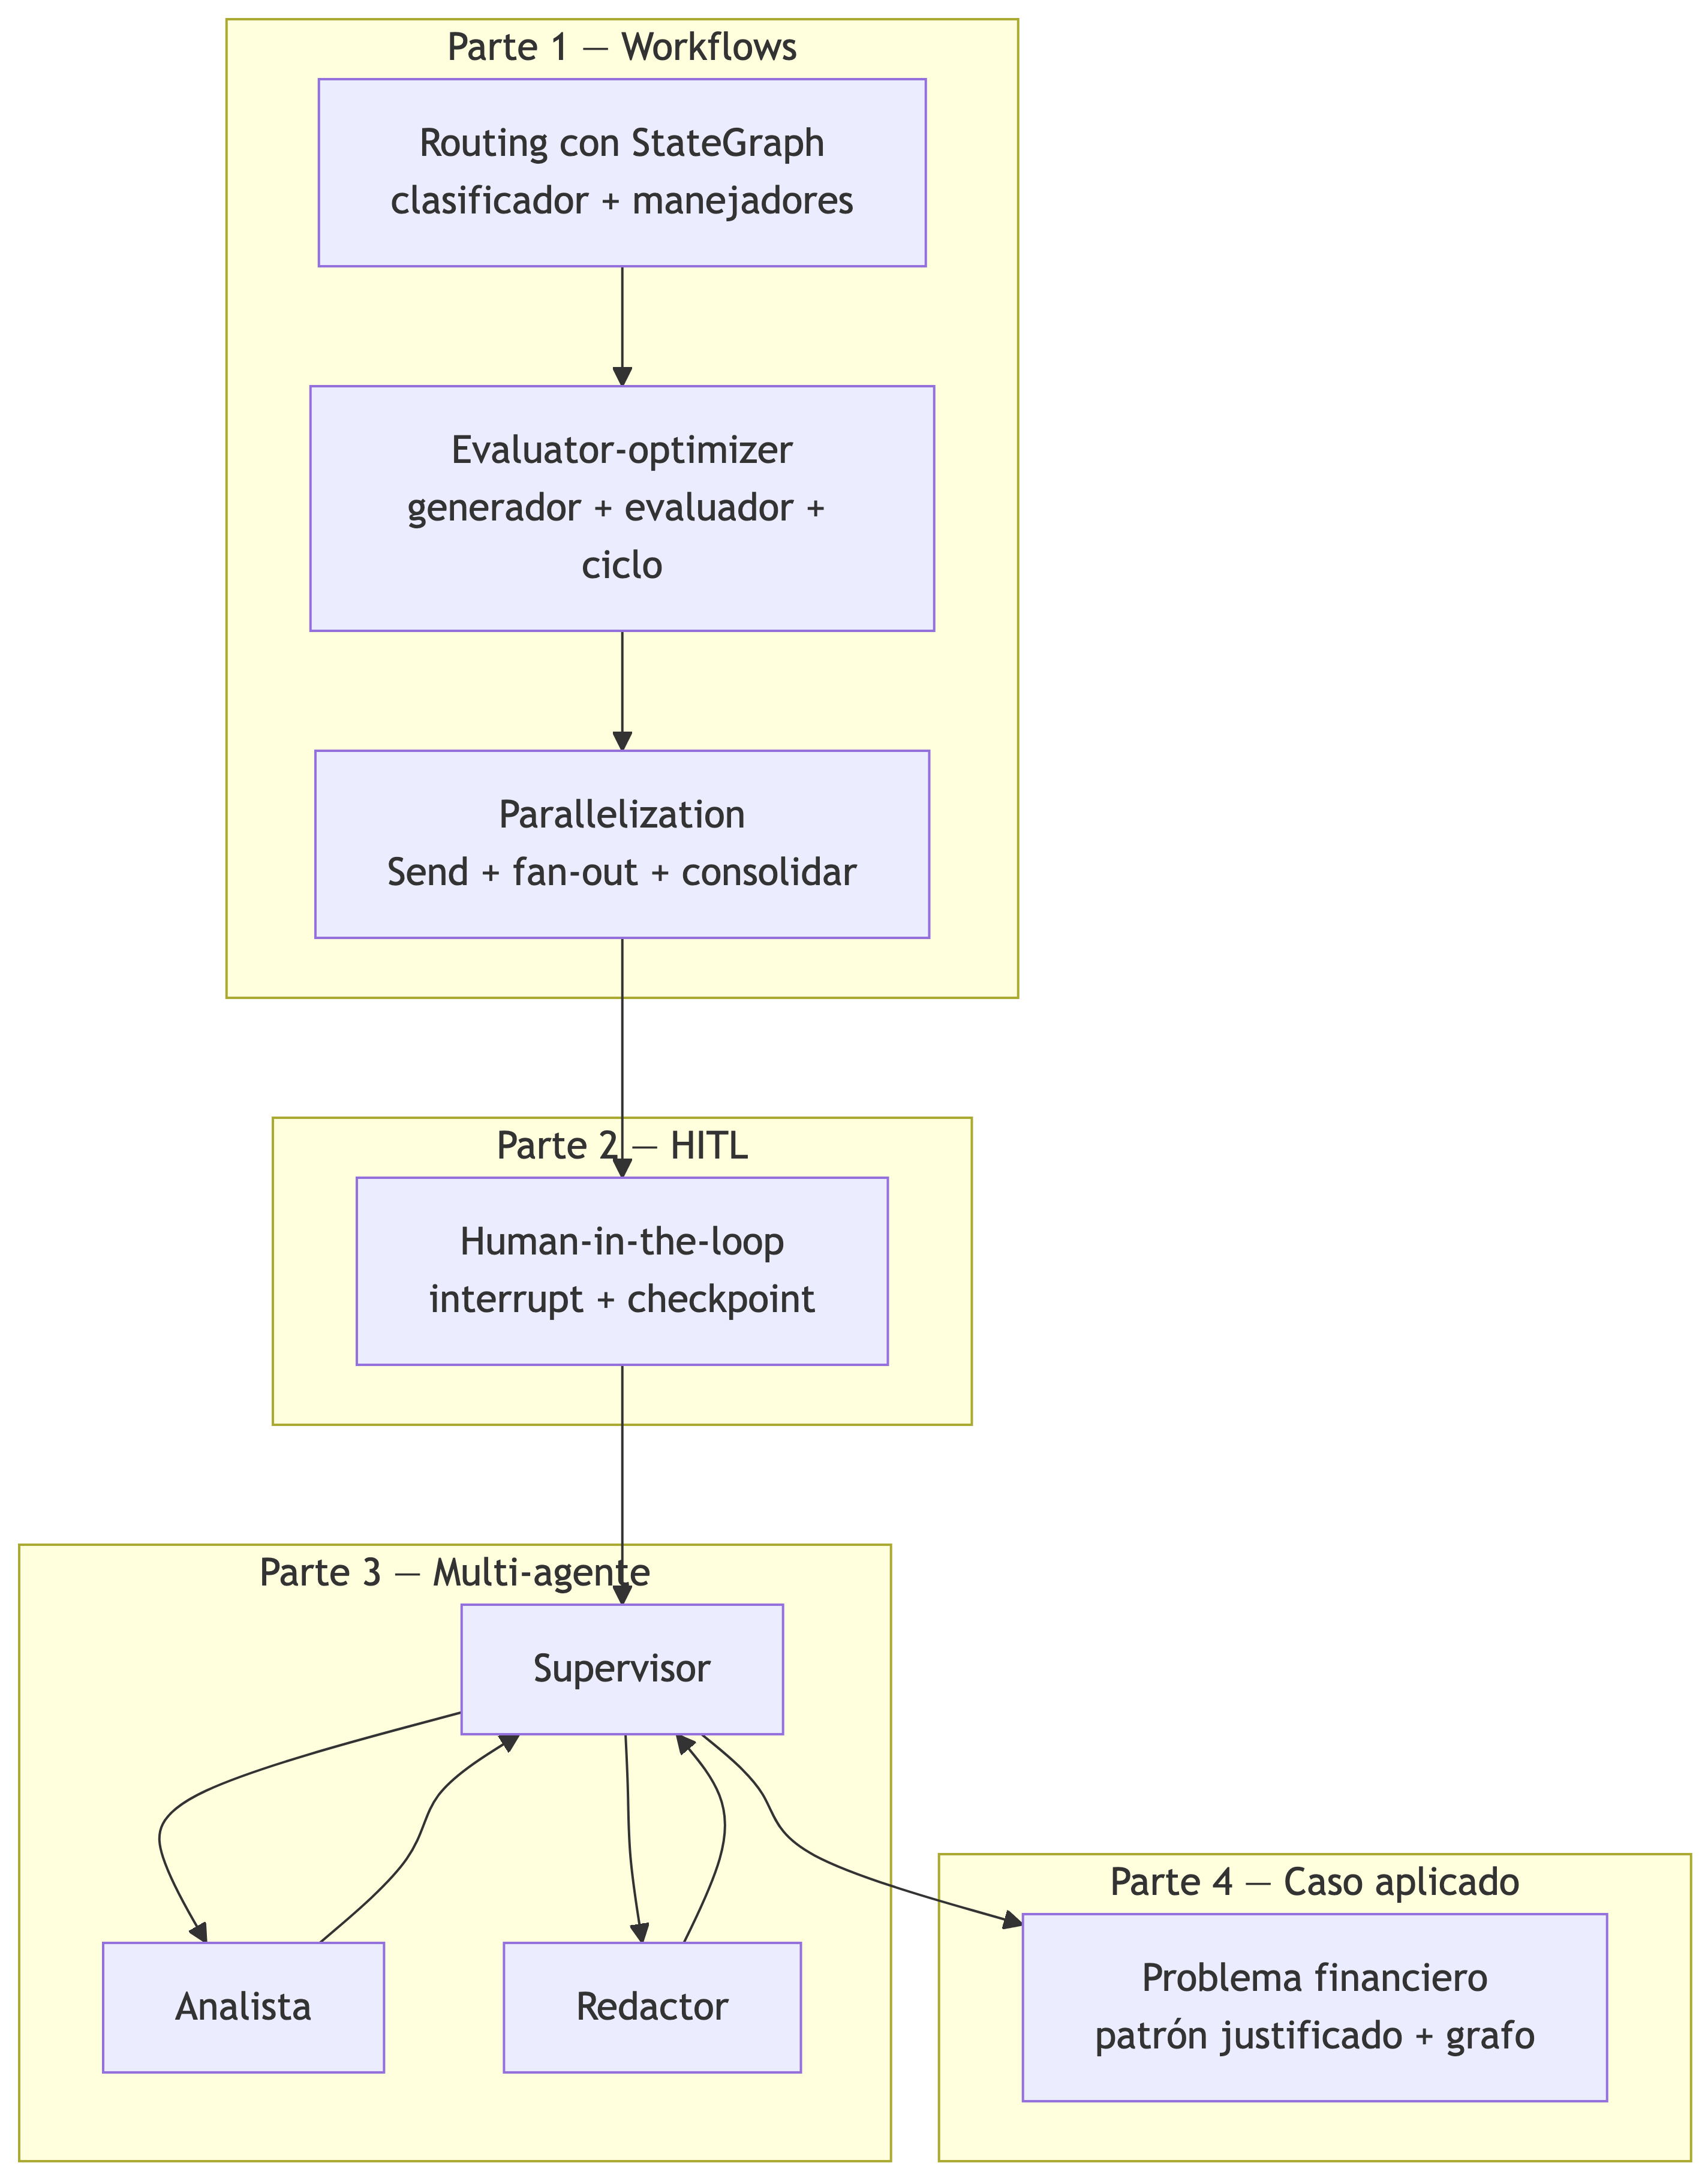
<figcaption>Figure 3</figcaption>
</figure>

# References